# Air-Traffic Demand Gap → U.S. Aerospace Manufacturing

**Independent research notebook | 2026-10-26 fixed snapshot | REPRODUCED MACRO PILOT / NOT PIT / NOT EQUITY ALPHA**

This study tests whether U.S. airline passenger-mile growth anticipates aerospace manufacturing output. It follows the 15-section canonical research structure and the K-Food v3 logic: falsifiable hypotheses, dated source register, fixed factor, purged expanding-window OOS, block-aware falsification, limitations and verdict. **All quantitative claims below come from code outputs; this is not a securities trading backtest.**

## 01. Abstract

**Question:** Does lagged air revenue passenger-mile growth, relative to manufacturing momentum, improve six-month-ahead U.S. aerospace production forecasts beyond persistence and macro baselines? The primary target is the G.17 NAICS 3364 industrial-production YoY log change at t+6. The study uses 201 aerospace/manufacturing monthly observations and 150 airline observations; no individual firm returns are included.

In [1]:
from pathlib import Path
import sys, json, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
import io
def showfig():
    buf=io.BytesIO()
    plt.gcf().savefig(buf,format='png',dpi=110,bbox_inches='tight')
    display(Image(data=buf.getvalue()))
    plt.close()
ROOT=Path.cwd()
assert (ROOT/'run_analysis.py').exists(), 'Run notebook from the study directory'
sys.path.insert(0,str(ROOT))
import run_analysis as ra
pd.set_option('display.max_columns',30)
print('Study root:',ROOT)
print('Predeclared six-month horizon:',ra.HORIZON,'| airline delay:',ra.AIR_LAG,'| G.17 delay:',ra.IP_LAG)

Study root: /mnt/data/aerospace_study
Predeclared six-month horizon: 6 | airline delay: 4 | G.17 delay: 2


In [2]:
raw=ra.load_data()
print('Raw rows:',len(raw),'| airline non-null:',raw.AIRRPMTSID11.notna().sum())
display(raw.head(3),raw.tail(3))

Raw rows: 201 | airline non-null: 150


,date,aerospace_ip,manufacturing_ip,AIRRPMTSID11
0,2010-01-01,84.8531,91.0661,NaN
1,2010-02-01,84.5264,91.0289,NaN
2,2010-03-01,85.7548,92.1506,NaN


,date,aerospace_ip,manufacturing_ip,AIRRPMTSID11
198,2026-07-01,100.3850,98.3983,NaN
199,2026-08-01,99.3433,98.1741,NaN
200,2026-09-01,99.2876,98.4387,NaN


The principal failure standard is **not** whether an in-sample coefficient is positive: the air-gap challenger must improve the macro baseline and historical mean on the same purged OOS origins.

## 02. Research Design & Hypotheses

**H1:** airline gap improves macro-control RMSE. **H2:** the gain survives exclusion of 2020–21 and alternative horizons. **H3:** the gain survives 1,000 block-shuffle placebos and ±20% formula perturbations. The counterthesis is that flight utilization drives engine aftermarket while aircraft production depends on multi-year order books, defense procurement and supply-chain bottlenecks.

In [3]:
design=pd.DataFrame({'test':['H1: incremental OOS','H2: regimes/horizons','H3: block placebo / weights'], 'success_rule':['macro RMSE − full RMSE > 0 and full < historical mean','positive in 2020–21 exclusion and 3m/12m horizons','not explained by block shuffle and robust weight signs']})
display(design)

,test,success_rule
0,H1: incremental OOS,macro RMSE − full RMSE > 0 and full < historic...
1,H2: regimes/horizons,positive in 2020–21 exclusion and 3m/12m horizons
2,H3: block placebo / weights,not explained by block shuffle and robust weig...


## 03. Industry Context

The [Aerospace Industries Association 2026 Facts & Figures](https://www.aia-aerospace.org/news/2026-aia-facts-figures-u-s-aerospace-defense-industry-leads-the-world-with-1-trillion-in-sale/) reports **$988.6B** of 2025 U.S. aerospace-and-defense sales and **$506B** of direct output. These are broad A&D totals, **not** the NAICS 3364 index level. Commercial aviation and defense procurement have different demand cycles, while a 2017=100 industrial production index is not a revenue series.

In [4]:
context=pd.DataFrame({'mechanism':['airline traffic → fleet replacement','flight utilization → maintenance','defense procurement → factory output','OEM capacity/supply-chain → factory output'], 'predicted_relation':['potentially positive but slow','positive aftermarket, weaker G.17 link','can overwhelm civilian signal','can sever demand-output link'], 'measured_here':['air passenger miles only','not directly','not directly','not directly']})
display(context)

,mechanism,predicted_relation,measured_here
0,airline traffic → fleet replacement,potentially positive but slow,air passenger miles only
1,flight utilization → maintenance,"positive aftermarket, weaker G.17 link",not directly
2,defense procurement → factory output,can overwhelm civilian signal,not directly
3,OEM capacity/supply-chain → factory output,can sever demand-output link,not directly


## 04. Data & Source Integrity

**Source grades:** A = original federal FRED table directly inspected; B = official federal series reused from previously frozen and manually transcribed repository studies; C = industry association context. `data/source_register.csv` records exact URLs, publisher, release date, coverage, units and revisions. All 201 aerospace monthly observations were parsed from the FRED table; independent checks of 2010-01, 2020-04 and 2026-09 are included. Historical row-by-row comparison of reused inputs remains pending.

In [5]:
sources=pd.read_csv(ROOT/'data/source_register.csv')
display(sources[['source_id','grade','series_or_document','release_or_publication_date','observation_period','revision_vintage']])

,source_id,grade,series_or_document,release_or_publication_date,observation_period,revision_vintage
0,G17_AERO,A,IPG3364S,2026-10-16,2010-01 through 2026-09,Latest revised snapshot on 2026-10-26; histori...
1,G17_MFG,B,IPMAN,2026-10-16,2010-01 through 2026-09,Previously manually transcribed fixed snapshot...
2,BTS_AIR,B,AIRRPMTSID11,2026-10-01,2014-01 through 2026-06,Previously manually transcribed fixed snapshot...
3,AIA_2026,C,2026 Facts and Figures,2026-06-25,2025,Industry report based on S&P Global Market Int...
4,BA_2025,B,2025 annual segment results,2026-01-27,2025,2025 release only; historical vintage panel no...
5,GE_2025,B,Standalone company annual report release,2025-02-03,2024,2025 release; no historical exposure panel
6,RTX_2025,B,2025 annual segment results,2026-01-27,2025,2025 release; no historical exposure panel


In [6]:
print('Raw SHA-256:',hashlib.sha256((ROOT/'data/frozen_observations_2026-10-26.csv').read_bytes()).hexdigest())
assert len(raw)==201 and raw.date.is_unique
assert np.isclose(raw.loc[raw.date.eq('2010-01-01'),'aerospace_ip'].iloc[0],84.8531)
assert np.isclose(raw.loc[raw.date.eq('2020-04-01'),'aerospace_ip'].iloc[0],54.3996)
assert np.isclose(raw.loc[raw.date.eq('2026-09-01'),'aerospace_ip'].iloc[0],99.2876)
print('Three independently viewed FRED aerospace spot checks: PASS')

Raw SHA-256: 5b03cac3a7368d1121a83c66e751d39bfcdbfd5c146ea6ed1b43f3f6ebb6c114
Three independently viewed FRED aerospace spot checks: PASS


In [7]:
print('Missing by column:')
display(raw.isna().sum().to_frame('missing_rows'))
print('Airline observed window:',raw.loc[raw.AIRRPMTSID11.notna(),'date'].min().date(),raw.loc[raw.AIRRPMTSID11.notna(),'date'].max().date())

Missing by column:


,missing_rows
date,0
aerospace_ip,0
manufacturing_ip,0
AIRRPMTSID11,51


Airline observed window: 2014-01-01 2026-06-01


## 05. Point-in-Time Availability

At formation t, airline signal ends at **t−4 months**, G.17 controls at **t−2 months**; a training label from formation s is allowed only if **s+6+1≤t**. These are modeling buffers, **not** historical release-vintage verification. Latest-revised G.17 and BTS values may differ from original releases; exact historical timestamps and revisions are UNKNOWN.

In [8]:
d=ra.panel()
display(d[['date','origin_month','aero_mom','mfg_mom','air_mom','air_gap','target']].head(5))
print('Complete formation rows:',len(d),'| first/last:',d.date.min().date(),d.date.max().date())

,date,origin_month,aero_mom,mfg_mom,air_mom,air_gap,target
0,2015-05-01,64,5.771754,-0.241872,3.011121,3.240304,-7.184075
1,2015-06-01,65,4.339921,-0.256493,3.136490,3.378589,-7.589850
2,2015-07-01,66,2.268571,-0.480376,2.802195,3.269533,-8.702449
3,2015-08-01,67,0.660998,-1.189879,2.894242,4.059076,-10.200945
4,2015-09-01,68,-1.621728,-0.870481,3.439335,4.280409,-10.217782


Complete formation rows: 131 | first/last: 2015-05-01 2026-03-01


In [9]:
o=ra.forecast(d)
first=o.iloc[0]; train=d[d.origin_month+ra.HORIZON+ra.TARGET_RELEASE_BUFFER<=first.origin_month]
print('First OOS formation:',first.date,'| training labels available:',len(train),'| last admitted training origin:',train.date.max().date())
assert len(train)==first.n_train
assert (train.origin_month+7<=first.origin_month).all()
print('Target-release purge: PASS')

First OOS formation: 2019-11-01 | training labels available: 48 | last admitted training origin: 2019-04-01
Target-release purge: PASS


## 06. Factor Construction

For series X define `g^X_t=100·ln(X_t/X_(t−12))`. Use `a_t=g^AIR_(t−4)`, `m_t=g^MFG_(t−2)`, `p_t=g^AERO_(t−2)` and fixed `F_t=30·tanh((a_t−m_t)/30)`. Target `y_t=g^AERO_(t+6)`. The scale 30 and Ridge penalty α=10 are fixed; only training-window feature means and standard deviations are fitted.

In [10]:
sample=d.iloc[10]
recomputed=30*np.tanh((sample.air_mom-sample.mfg_mom)/30)
print('Sample origin:',sample.date.date(),'| factor saved:',round(sample.air_gap,6),'| independently recomputed:',round(recomputed,6))
assert np.isclose(sample.air_gap,recomputed)

Sample origin: 2016-03-01 | factor saved: 5.249988 | independently recomputed: 5.249988


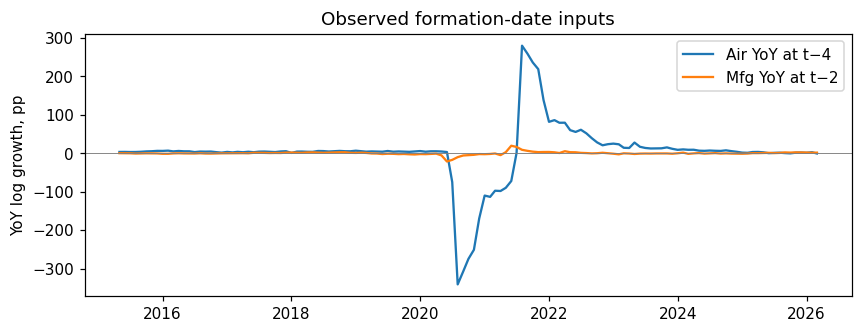

In [11]:
fig,ax=plt.subplots(figsize=(9,3.1));ax.plot(d.date,d.air_mom,label='Air YoY at t−4');ax.plot(d.date,d.mfg_mom,label='Mfg YoY at t−2');ax.axhline(0,color='gray',lw=.6);ax.set_ylabel('YoY log growth, pp');ax.set_title('Observed formation-date inputs');ax.legend();showfig()

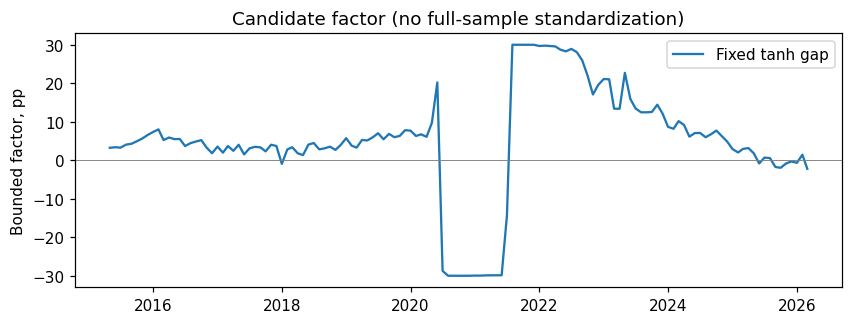

In [12]:
fig,ax=plt.subplots(figsize=(9,3));ax.plot(d.date,d.air_gap,label='Fixed tanh gap');ax.axhline(0,color='gray',lw=.6);ax.set_ylabel('Bounded factor, pp');ax.set_title('Candidate factor (no full-sample standardization)');ax.legend();showfig()

## 07. Exposure & Transmission

Dated company exposure is **qualitative**. Boeing commercial aircraft, GE Aerospace propulsion/aftermarket, and RTX Collins/Pratt & Whitney/defense have distinct revenue channels. There is no justified monthly company exposure matrix or historical constituent universe. **Leave-one-company-out is inapplicable**; it is not replaced with fabricated firm data.

In [13]:
exposure=pd.read_csv(ROOT/'data/company_exposure_map.csv')
display(exposure[['company','exposure_type','qualitative_direction','as_of','weight']])

,company,exposure_type,qualitative_direction,as_of,weight
0,Boeing,Commercial airplanes / defense / global services,Commercial airplane demand may respond to airl...,2026-01-27,UNKNOWN
1,GE Aerospace,Commercial and defense engines / aftermarket,Flight activity directly influences engine aft...,2025-02-03,UNKNOWN
2,RTX,Pratt and Whitney / Collins / Raytheon,Air travel may affect commercial engine and pa...,2026-01-27,UNKNOWN


Aerospace output is a U.S. industry aggregate, not a value-weighted portfolio of those three companies. The ±20% robustness test changes the *economic formula weights*, not security holdings.

## 08. Outcomes & Baselines

**Common origins:** historical target mean; direct lagged aerospace YoY persistence; two-control Ridge (`p_t,m_t`); full Ridge (`p_t,m_t,F_t`); air-only; no-manufacturing ablation. Each model uses the same target, purge and origins. Corporate fundamentals and total-return/benchmark-adjusted equity returns are **NOT TESTED**; return IC/spread is **N/A**, not zero.

In [14]:
print('OOS observations:',len(o),'| date range:',o.date.min(),o.date.max(),'| training sample range:',o.n_train.min(),o.n_train.max())
display(o.head(3),o.tail(3))

OOS observations: 77 | date range: 2019-11-01 2026-03-01 | training sample range: 48 124


,date,origin_month,actual,n_train,mean,persistence,macro,full,air_only,no_mfg
0,2019-11-01,118,-30.903693,48,-3.476817,-9.341263,1.028714,1.086102,-5.911572,-6.261687
1,2019-12-01,119,-31.318266,49,-3.497181,-5.726351,3.382462,0.857045,-7.358784,-6.966724
2,2020-01-01,120,-24.570564,50,-3.519556,-4.474654,1.108509,-2.420670,-7.169000,-6.655205


,date,origin_month,actual,n_train,mean,persistence,macro,full,air_only,no_mfg
74,2026-01-01,192,6.283282,122,-1.241293,26.850057,5.112231,6.118478,-0.890725,4.257807
75,2026-02-01,193,5.796586,123,-1.156304,17.488088,3.225254,3.906883,-0.920578,2.634295
76,2026-03-01,194,4.593909,124,-1.078573,9.212299,1.107685,1.963057,-0.617694,1.621102


In [15]:
sc=ra.scorecard(o)
display(sc.round(3))
assert (sc.n==len(o)).all()

,model,n,rmse_pp,mae_pp,pearson_ic
0,mean,77,13.810,11.800,0.042
1,persistence,77,17.539,12.807,0.112
2,macro,77,16.967,13.005,-0.064
3,full,77,19.890,16.489,0.262
4,air_only,77,25.421,18.844,0.318
5,no_mfg,77,20.374,16.538,0.321


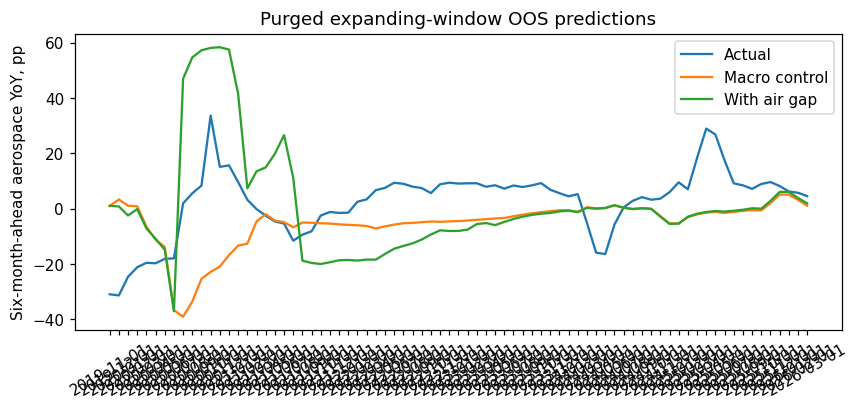

In [16]:
fig,ax=plt.subplots(figsize=(9,3.5));ax.plot(o.date,o.actual,label='Actual');ax.plot(o.date,o.macro,label='Macro control');ax.plot(o.date,o.full,label='With air gap');ax.legend();ax.set_title('Purged expanding-window OOS predictions');ax.set_ylabel('Six-month-ahead aerospace YoY, pp');plt.xticks(rotation=30);showfig()

## 09. Empirical Findings

The predeclared improvement is `RMSE(macro) − RMSE(full)`. **Positive is improvement, negative is deterioration.** Pearson forecast/outcome correlation is secondary and cannot substitute for calibrated prediction loss.

In [17]:
delta=ra.rmse(o.actual,o.macro)-ra.rmse(o.actual,o.full)
print(f'Macro-minus-full RMSE: {delta:.3f} pp; mean-minus-full: {ra.rmse(o.actual,o["mean"])-ra.rmse(o.actual,o.full):.3f} pp')
print('Hypothesis H1 supported?',delta>0 and ra.rmse(o.actual,o.full)<ra.rmse(o.actual,o['mean']))

Macro-minus-full RMSE: -2.923 pp; mean-minus-full: -6.080 pp
Hypothesis H1 supported? False


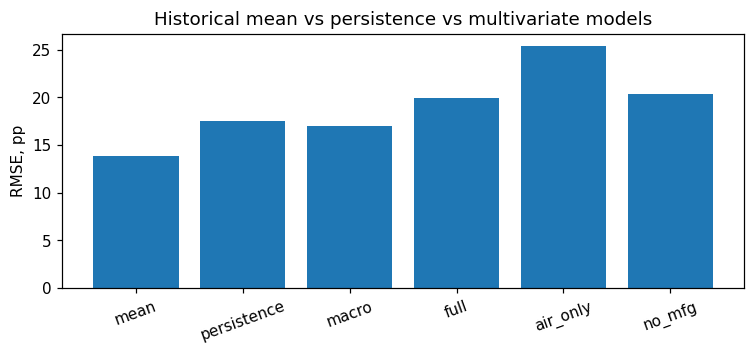

In [18]:
fig,ax=plt.subplots(figsize=(8,3));ax.bar(sc.model,sc.rmse_pp);ax.set_ylabel('RMSE, pp');ax.set_title('Historical mean vs persistence vs multivariate models');plt.xticks(rotation=20);showfig()

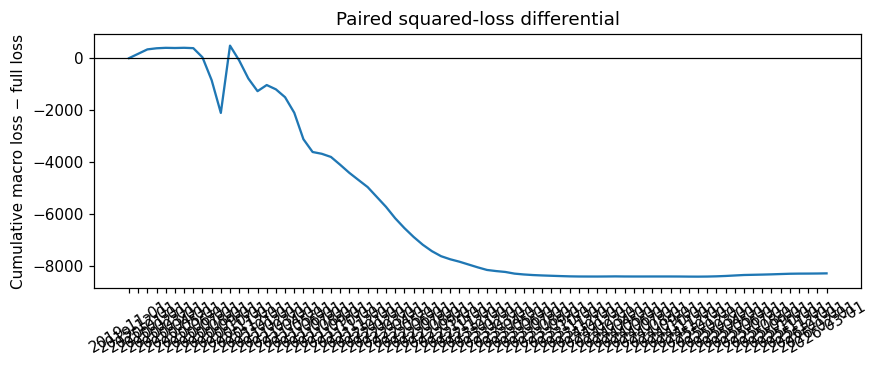

In [19]:
loss=(o.actual-o.macro)**2-(o.actual-o.full)**2
fig,ax=plt.subplots(figsize=(9,3));ax.plot(o.date,loss.cumsum());ax.axhline(0,color='black',lw=.8);ax.set_ylabel('Cumulative macro loss − full loss');ax.set_title('Paired squared-loss differential');plt.xticks(rotation=30);showfig()

The factor can correlate with the direction of production changes while still **increasing squared forecast error** during regime changes. The scorecard and cumulative-loss plot, rather than a selected positive coefficient, determine the verdict.

## 10. Robustness & Placebos

Block shuffling preserves within-12-month order while reassigning the factor's annual blocks; each of **1,000** draws refits the expanding-window model. This is a **heuristic placebo**, not an exact p-value because temporal regimes and overlapping targets violate exchangeability. Paired circular-block bootstrap (**2,000** draws) quantifies forecast-loss sensitivity. Economic formula weights vary independently ±20% in **1,000** refits.

In [20]:
# Full 1,000/2,000/1,000 draw analyses are generated by run_analysis.py before publication.
# This notebook verifies saved draw counts and independently recomputes all OOS forecasts.
metrics=json.loads((ROOT/'results/metrics.json').read_text())
assert metrics['n_oos']==len(o)
assert metrics['block_placebo_draws']==1000 and metrics['bootstrap_draws']==2000 and metrics['exposure_draws']==1000
saved=pd.read_csv(ROOT/'results/walk_forward_oos.csv')
assert np.allclose(saved[['macro','full']],o[['macro','full']])
print('Saved heavy falsifications + independent OOS reproduction: PASS')

Saved heavy falsifications + independent OOS reproduction: PASS


Exploratory shuffled-tail fraction: 0.932


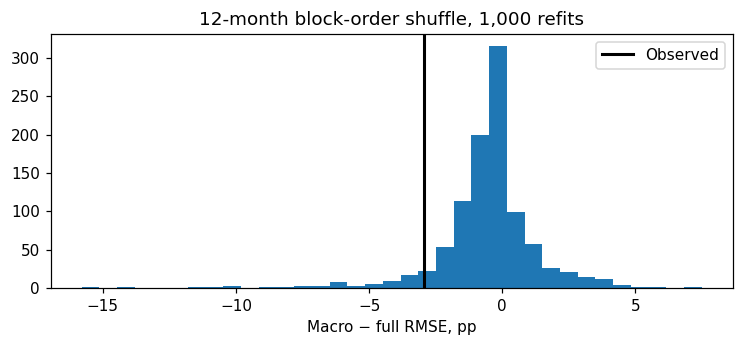

In [21]:
p=pd.read_csv(ROOT/'results/block_placebo_1000.csv')
print('Exploratory shuffled-tail fraction:',round((p.delta_rmse_pp>=delta).mean(),3))
fig,ax=plt.subplots(figsize=(8,3));ax.hist(p.delta_rmse_pp,bins=35);ax.axvline(delta,color='black',lw=2,label='Observed');ax.set_xlabel('Macro − full RMSE, pp');ax.legend();ax.set_title('12-month block-order shuffle, 1,000 refits');showfig()

Bootstrap 95% interval: [-6.511 -0.369] | 2,000 paired circular 12-month blocks


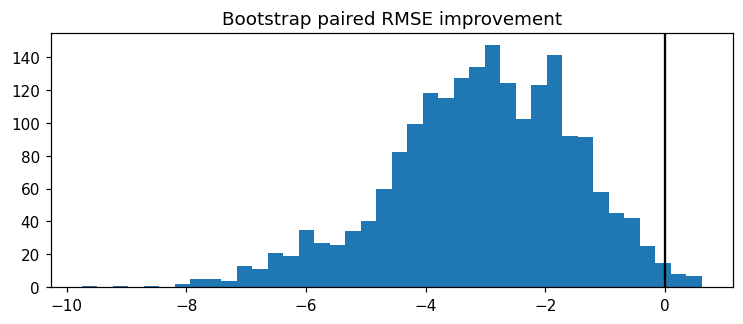

In [22]:
b=pd.read_csv(ROOT/'results/bootstrap_2000.csv');ci=np.quantile(b.delta_macro_full,[.025,.975])
print('Bootstrap 95% interval:',ci.round(3),'| 2,000 paired circular 12-month blocks')
fig,ax=plt.subplots(figsize=(8,3));ax.hist(b.delta_macro_full,bins=40);ax.axvline(0,color='black');ax.set_title('Bootstrap paired RMSE improvement');showfig()

Fraction of perturbations with positive gain: 0.0


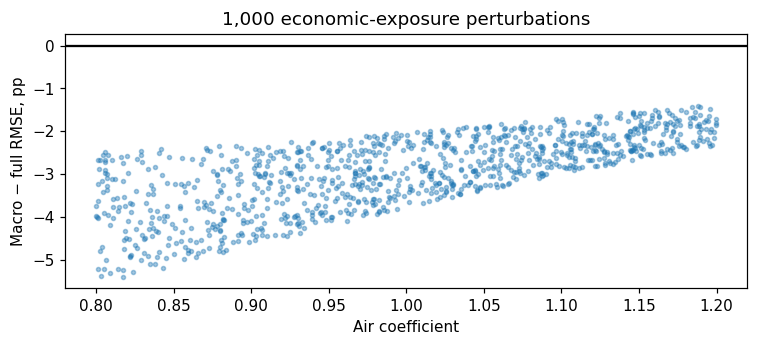

In [23]:
pert=pd.read_csv(ROOT/'results/exposure_1000.csv')
print('Fraction of perturbations with positive gain:',round((pert.delta_macro_full>0).mean(),3))
fig,ax=plt.subplots(figsize=(8,3));ax.scatter(pert.w_air,pert.delta_macro_full,s=7,alpha=.4);ax.axhline(0,color='black');ax.set_xlabel('Air coefficient');ax.set_ylabel('Macro − full RMSE, pp');ax.set_title('1,000 economic-exposure perturbations');showfig()

In [24]:
print('Ablation scorecard:')
display(sc[sc.model.isin(['macro','full','air_only','no_mfg'])].round(3))

Ablation scorecard:


,model,n,rmse_pp,mae_pp,pearson_ic
2,macro,77,16.967,13.005,-0.064
3,full,77,19.890,16.489,0.262
4,air_only,77,25.421,18.844,0.318
5,no_mfg,77,20.374,16.538,0.321


## 11. Regime Sensitivity

Change forecast horizon to 3 or 12 months, airline delay to 6 months, or G.17 delay to 3 months. Separately **score** the unchanged OOS predictions excluding 2020–21, rather than retraining a post-hoc model. A pre-2020 slice with only two origins is too small for inference.

In [25]:
rob=pd.read_csv(ROOT/'results/robustness.csv')
display(rob.round(3))

,test,n,macro_minus_full_rmse_pp,mean_minus_full_rmse_pp
0,3-month,83,-6.286,-6.899
1,12-month,65,-4.083,-5.623
2,air lag 6m,75,-0.368,-3.384
3,ip lag 3m,77,-4.231,-8.618
4,pre-2020,2,1.263,-4.458
5,pandemic-2020-2021,24,-4.070,-12.152
6,post-2021,51,-2.639,-2.225
7,exclude-2020-2021,53,-2.220,-2.347


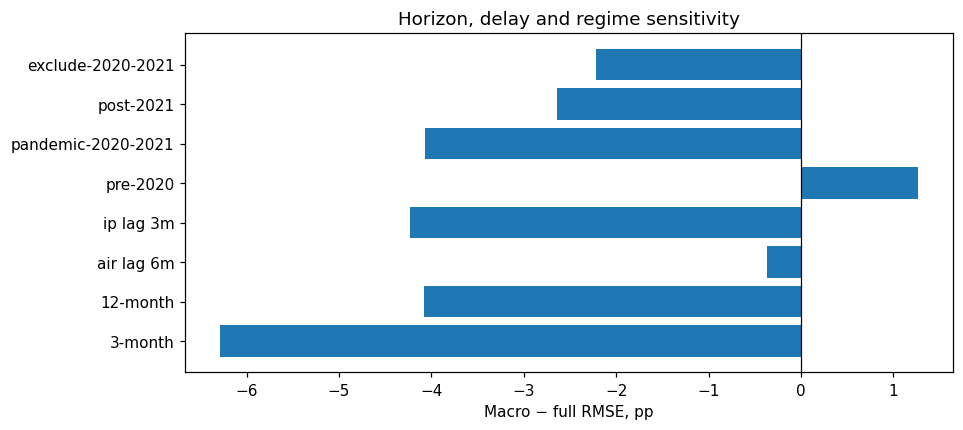

In [26]:
fig,ax=plt.subplots(figsize=(9,4));ax.barh(rob.test,rob.macro_minus_full_rmse_pp);ax.axvline(0,color='black',lw=.8);ax.set_title('Horizon, delay and regime sensitivity');ax.set_xlabel('Macro − full RMSE, pp');showfig()

In [27]:
loo=pd.read_csv(ROOT/'results/leave_one_year_out.csv')
display(loo.round(3))
print('Leave-one-year-out gain positive in',int((loo.delta_macro_full>0).sum()),'of',len(loo),'exclusions')

,excluded_year,n,delta_macro_full
0,2019,75,-3.154
1,2020,65,-3.856
2,2021,65,-1.778
3,2022,65,-2.069
4,2023,65,-3.107
5,2024,65,-3.236
6,2025,65,-3.442
7,2026,74,-2.986


Leave-one-year-out gain positive in 0 of 8 exclusions


## 12. Bias Audit & Verdict

**PIT:** all three series are revised snapshots; initial release vintages UNKNOWN. **Selection:** this industry was chosen after several negative industry pilots, so across-study multiple testing is material. **Regime:** 2020 and post-pandemic production constraints are not stable. **Survivorship:** national index composition/revisions, not a historical company universe. **Causality:** no aircraft order backlog, exports, defense controls or fleet data. **Costs:** no stock returns, transactions, capacity or slippage; no trading claim. **Verdict: NEGATIVE REPRODUCED MACRO PILOT; NOT PIT; NOT EQUITY ALPHA.**

In [28]:
verdict={'H1_incremental_rmse_positive':bool(delta>0),'H2_exclude_pandemic_positive':bool(rob.loc[rob.test.eq('exclude-2020-2021'),'macro_minus_full_rmse_pp'].iloc[0]>0),'H3_exposure_majority_positive':bool((pert.delta_macro_full>0).mean()>.5),'historical_PIT_verified':False,'equity_alpha_established':False}
display(pd.DataFrame([verdict]).T.rename(columns={0:'result'}))

,result
H1_incremental_rmse_positive,False
H2_exclude_pandemic_positive,False
H3_exposure_majority_positive,False
historical_PIT_verified,False
equity_alpha_established,False


## 13. Reproduction

From a clean checkout install `requirements.txt`, run `python run_analysis.py`, then `python -m pytest tests -q`, and execute this notebook with nbconvert/nbclient. All plots and tables above are computed from the frozen input, and results have fixed seeds. Root `scripts/validate_studies.py` is a **structural** gate, not proof of real-time vintage validity.

In [29]:
import subprocess
p_test=subprocess.run([sys.executable,'-m','pytest','tests','-q'],cwd=ROOT,capture_output=True,text=True)
print(p_test.stdout)
assert p_test.returncode==0,p_test.stderr

............                                                             [100%]
12 passed in 0.72s



In [30]:
print('Published results:')
for name in ['metrics.json','scorecard.csv','walk_forward_oos.csv','block_placebo_1000.csv','bootstrap_2000.csv','exposure_1000.csv','robustness.csv']:
 pth=ROOT/'results'/name
 print(name,pth.stat().st_size,'bytes')
assert len(list((ROOT/'figures').glob('*.png')))>=3

Published results:
metrics.json 1329 bytes
scorecard.csv 438 bytes
walk_forward_oos.csv 11775 bytes
block_placebo_1000.csv 23670 bytes
bootstrap_2000.csv 86137 bytes
exposure_1000.csv 61022 bytes
robustness.csv 480 bytes


## 14. Next-Stage Protocol

Acquire actual ALFRED G.17 historical vintages and BTS initial-release files; re-audit all 201 aerospace and reused manufacturing/air rows; timestamp each observation as available. Add FAA deliveries, order backlogs, defense contracts and supply-chain lead times. Only then construct historical firm-segment revenue exposure panels, independent earnings outcomes, dividend-adjusted total returns, transaction costs and an untouched holdout.

In [31]:
next_steps=pd.DataFrame({'priority':[1,2,3,4],'data':['G.17/BTS first-release vintages','FAA orders, fleet and deliveries','Dated BA/GE/RTX segment fundamentals','Adjusted returns + benchmark + costs'],'current_status':['UNKNOWN','NOT COLLECTED','NOT COLLECTED','NOT COLLECTED']})
display(next_steps)

,priority,data,current_status
0,1,G.17/BTS first-release vintages,UNKNOWN
1,2,"FAA orders, fleet and deliveries",NOT COLLECTED
2,3,Dated BA/GE/RTX segment fundamentals,NOT COLLECTED
3,4,Adjusted returns + benchmark + costs,NOT COLLECTED


## 15. Sources & Artifacts

Primary source: [Federal Reserve aerospace G.17](https://fred.stlouisfed.org/data/IPG3364S) (updated 2026-10-16). Controls: [G.17 manufacturing](https://fred.stlouisfed.org/data/IPMAN) (2026-10-16) and [BTS air passenger miles](https://fred.stlouisfed.org/data/AIRRPMTSID11) (2026-10-01). Company mapping: [Boeing](https://investors.boeing.com/investors/news/press-release-details/2026/Boeing-Reports-Fourth-Quarter-Results/default.aspx), [GE Aerospace](https://www.geaerospace.com/news/articles/smooth-takeoff-ge-aerospace-releases-first-annual-report-standalone-company), [RTX](https://www.rtx.com/news/news-center/2026/01/27/rtx-reports-2025-results-and-announces-2026-outlook-). Full source register, frozen data, analysis, tests, results and computed figures accompany this notebook.

In [32]:
summary={'observations':len(raw),'oos_origins':len(o),'rmse_mean_pp':round(ra.rmse(o.actual,o['mean']),3),'rmse_macro_pp':round(ra.rmse(o.actual,o.macro),3),'rmse_full_pp':round(ra.rmse(o.actual,o.full),3),'macro_minus_full_pp':round(delta,3),'bootstrap_ci_pp':ci.round(3).tolist(),'vintage':'latest revised, NOT PIT','verdict':'FAILED incremental macro prediction'}
display(pd.DataFrame([summary]).T.rename(columns={0:'value'}))

,value
observations,201
oos_origins,77
rmse_mean_pp,13.81
rmse_macro_pp,16.967
rmse_full_pp,19.89
macro_minus_full_pp,-2.923
bootstrap_ci_pp,"[-6.511, -0.369]"
vintage,"latest revised, NOT PIT"
verdict,FAILED incremental macro prediction
